# Object Detection with YOLO

*   Object Detection
*   YOLO for Object Detection
    * Dataset formats
    * Fine-tuning with a custom dataset
---

# YOLO for Object Detection

*   There are several open source implementations of each version of YOLO.
*   For this exercise, we will not be implementing the YOLO from scratch as it is a challenging model and requires many customized elements.
*   We will use the official Ultralytics YOLO11 implementation for this exercise.
*  The Ultralytics YOLO implementation is available as a Python package that can be installed via pip.

In [ ]:
# %pip installs into the kernel's own Python (the project venv); "!pip" may use another one
%pip install ultralytics

In [2]:
# check
import ultralytics
ultralytics.checks()

Ultralytics 8.4.216 🚀 Python-3.10.22 torch-2.14.1 CPU (Apple M2 Pro)
Setup complete ✅ (10 CPUs, 16.0 GB RAM, 186.2/460.4 GB disk)


## YOLO model - first test

In [3]:
from ultralytics import YOLO

# Load a model
# model = YOLO('yolo11n.yaml')  # build a new model from scratch
model = YOLO('yolo11n.pt')  # load a pretrained model (recommended for training)
# Use the model
results = model('https://ultralytics.com/images/bus.jpg')  # predict on an image


image 1/1 /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/bus.jpg: 640x480 4 persons, 1 bus, 61.3ms
Speed: 5.5ms preprocess, 61.3ms inference, 2.2ms postprocess per image at shape (1, 3, 640, 480)


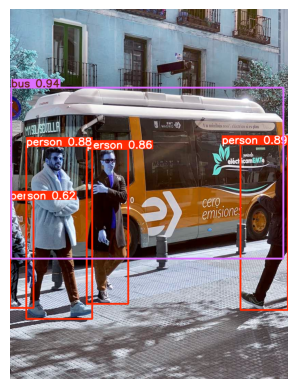

In [4]:
import matplotlib.pyplot as plt
plt.imshow(results[0].plot())
plt.axis('off')
plt.show()

In [6]:
# Understanding the Results object
print(type(results[0]))
print(dir(results[0]))
print(help(results[0]))

<class 'ultralytics.engine.results.Results'>
['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_apply', '_keys', 'boxes', 'colors', 'cpu', 'cuda', 'depth', 'keypoints', 'masks', 'merge_tiles', 'names', 'new', 'numpy', 'obb', 'orig_img', 'orig_shape', 'path', 'plot', 'probs', 'save', 'save_crop', 'save_dir', 'save_txt', 'semantic_mask', 'show', 'speed', 'summary', 'to', 'to_csv', 'to_df', 'to_json', 'update', 'verbose']
Help on Results in module ultralytics.engine.results object:

class Results(ultralytics.utils.SimpleClass, ultralytics.utils.DataExportMixin)
 |  Results(orig_img: 'np.ndarray', path: 'str', names: 'dict[int, str]', boxes: 'torch.Tensor | N

In [7]:
# Understanding the Boxes object
print(type(results[0].boxes))
print(dir(results[0].boxes))
print(help(results[0].boxes))

<class 'ultralytics.engine.results.Boxes'>
['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattr__', '__getattribute__', '__getitem__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', '_convert', 'cls', 'conf', 'cpu', 'cuda', 'data', 'id', 'is_track', 'numpy', 'orig_shape', 'shape', 'to', 'xywh', 'xywhn', 'xyxy', 'xyxyn']
Help on Boxes in module ultralytics.engine.results object:

class Boxes(BaseTensor)
 |  Boxes(boxes: 'torch.Tensor | np.ndarray', orig_shape: 'tuple[int, int]') -> 'None'
 |  
 |  A class for managing and manipulating detection boxes.
 |  
 |  This class provides comprehensive functionality for handling detection boxes, including their coordinates,
 |  confidence scores, class labels, and optional tracking IDs. It supports vari

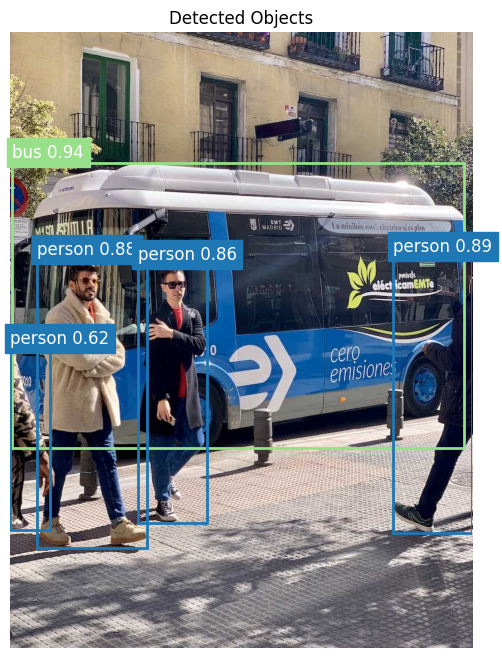

In [9]:
# Plotting the results in a more customizable way can be done using matplotlib by accessing
# the boxes and labels from the results object.
import cv2
import matplotlib

boxes = results[0].boxes
labels = results[0].names

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.imshow(cv2.cvtColor(results[0].orig_img, cv2.COLOR_BGR2RGB))

# define a color map for different classes
colors = matplotlib.colormaps.get_cmap('tab20')

# plot each box
for box in boxes:
    x1, y1, x2, y2 = box.xyxy[0].cpu()
    conf = box.conf[0].cpu()
    cls = int(box.cls[0])
    label = labels[cls]

    # create a rectangle patch
    rect = plt.Rectangle((x1, y1), x2 - x1, y2 - y1, linewidth=2, edgecolor=colors(cls), facecolor='none')
    ax.add_patch(rect)
    ax.text(x1, y1 - 10, f'{label} {conf:.2f}', color='white', fontsize=12, backgroundcolor=colors(cls))

plt.axis('off')
plt.title('Detected Objects')
plt.show()


# YOLO customization and training with custom data
*   In this exercise, we will fine-tune a pre-trained YOLO model on a custom dataset.
*   We will prepare the dataset in the required format.
*   We will customize the YOLO model configuration to fit our dataset.

We will use RoboFlow's blood cell detection dataset for this exercise:
https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na

This dataset contains microscopic images of different cells:

* PC - Platelets / Thrombocytes - Small, non-nucleated blood cells essential for hemostasis (stopping bleeding). They clump together to form a plug at the site of a damaged blood vessel wall.
* RBC - Red Blood Cells / Erythrocytes - The most abundant blood cells, responsible for transporting oxygen from the lungs to the body's tissues and carrying carbon dioxide back to the lungs.
* WBC - White Blood Cells / Leukocytes - These cells are the core components of the immune system, defending the body against infections, foreign invaders (bacteria, viruses), and abnormal cells.

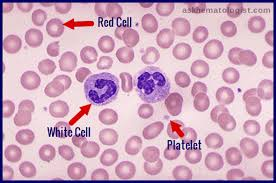

Reference:
```
@misc{
    blood-cell-st9na_dataset,
    title = { blood cell Dataset },
    type = { Open Source Dataset },
    author = { tumor },
    howpublished = { \url{ https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na } },
    url = { https://universe.roboflow.com/tumor-4iauk/blood-cell-st9na },
    journal = { Roboflow Universe },
    publisher = { Roboflow },
    year = { 2024 },
    month = { sep },
    note = { visited on 2025-11-17 },
    }

```



### Understanding the COCO and YOLO dataset formats

In [8]:
# COCO format annotation example
dummy_coco_annotation = {
    "images": [
        {
            "id": 1,
            "width": 640,
            "height": 480,
            "file_name": "image1.jpg"
        },
        {
            "id": 2,
            "width": 800,
            "height": 600,
            "file_name": "image2.jpg"
        }
    ],
    "annotations": [
        {
            "id": 1,
            "image_id": 1,
            "category_id": 1,
            "bbox": [100, 150, 200, 300],  # [x, y, width, height]
            "area": 60000,
            "iscrowd": 0
        },
        {
            "id": 2,
            "image_id": 2,
            "category_id": 1,
            "bbox": [50, 75, 100, 150],
            "area": 15000,
            "iscrowd": 0
        },
        {
            "id": 3,
            "image_id": 2,
            "category_id": 2,
            "bbox": [300, 400, 120, 180],
            "area": 5000,
            "iscrowd": 0
        }
    ],
    "categories": [
        {
            "id": 1,
            "name": "person"
        },
        {
            "id": 2,
            "name": "dog"
        }
    ]
}

YOLO expects the data to be in a different format:

```
├── data.yaml
├── test
│   ├── images
│   │   ├── 018239dc-02bb-5c9c-be33-0737ee53d592_jpg.rf.53258de6e413c4f33f824fb33c5883a3.jpg
│   └── labels
│       ├── 018239dc-02bb-5c9c-be33-0737ee53d592_jpg.rf.53258de6e413c4f33f824fb33c5883a3.txt
├── train
│   ├── images
│   └── labels
└── valid
    ├── images
    └── labels
```

data.yaml:
```
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 3
names: ['PC', 'RBC', 'WBC']
```


### Prepare data

Load the `_annotations.coco.json` from `blood_cell.v1i.coco/train` folder.

Our current data structure is following:

```
├── test
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_test_image.jpg
├── train
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_train_image.jpg
└── valid
│   ├── f92c6c01-26a6-571d-81b1-0e2e2d50a1a9_jpg.rf.857f296efb37cffab62976e16fcedc17.jpg
│   ├── another_val_image.jpg
```

We need to convert them to YOLO folder structure and create the missing label txt files and `data.yaml` file.

***Note that you can already download the same data in YOLO format from roboflow, but in most of the real-world scenarios, you will have to do this manually. This COCO to YOLO conversion is a simple exercise to get to understand it and be prepared in the future.***

Create a function `coco_to_yolo(input_folder, output_folder)` that does the following:
* Creates `images` and `labels` folder in `output_folder`.
* Copies all the image files (`.jpg, .png` etc) to the newly created `images` folder.
* Reads `input_folder/_annotations.coco.json` into a dictionary.
* Extracts annotations and reformats them into a YOLO format and write into a `{image_name}.txt` file inside the newly created `labels` folder. The content of `{image_name}.txt` should be as follows:
    ```
      class_id x_center y_center width height
      class_id x_center y_center width height
      ...
    ```
    where each line is one bounding box belonging to `{image_name}.jpg`.

Call the function three times:
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/train'), os.path.join(root_path, 'blood_cell.v1i.yolov11/train'))`
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/valid'), os.path.join(root_path, 'blood_cell.v1i.yolov11/valid'))`
* `coco_to_yolo(os.path.join(root_path, 'blood_cell.v1i.coco/test'), os.path.join(root_path, 'blood_cell.v1i.yolov11/test'))`


In [10]:
# Paths: works both locally (VS Code) and on Google Colab.
import os
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    # Drive folder that contains blood_cell.v1i.coco/ (change if needed)
    root_path = "/content/drive/MyDrive/Colab Notebooks/P9-Detection-YOLO"
    os.chdir(root_path)  # so runs/ and yolo11n.pt are stored on Drive and survive a restart
else:
    root_path = os.path.abspath(".")  # Set9/, the folder of this notebook

coco_root_path = os.path.join(root_path, "blood_cell.v1i.coco")  # input: COCO export
yolo_root_path = os.path.join(root_path, "blood_cell.v1i.yolov11")  # output of coco_to_yolo
# Roboflow's own YOLO export of the same images (optional): only used to check our conversion
roboflow_yolo_path = os.path.join(root_path, "blood cell.v1i.yolov11")
runs_path = os.path.join(root_path, "runs", "detect")  # training / validation outputs

CLASS_NAMES = ["PC", "RBC", "WBC"]  # YOLO class ids 0, 1, 2

assert os.path.isdir(coco_root_path), f"{coco_root_path} not found: check root_path"

In [11]:
import json
import shutil

IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}


def coco_to_yolo(input_folder, output_folder):
    images_dir = os.path.join(output_folder, "images")
    labels_dir = os.path.join(output_folder, "labels")
    os.makedirs(images_dir, exist_ok=True)
    os.makedirs(labels_dir, exist_ok=True)

    # 1. copy the images
    for f in os.listdir(input_folder):
        src = os.path.join(input_folder, f)
        if os.path.isfile(src) and os.path.splitext(f)[1].lower() in IMAGE_EXTS:
            shutil.copy(src, os.path.join(images_dir, f))

    # 2. read the COCO annotations
    with open(os.path.join(input_folder, "_annotations.coco.json")) as f:
        coco = json.load(f)

    # COCO category id -> YOLO class id, matched by name.
    # Roboflow adds a dummy category 0 ("1-2-3-SmhR") and then PC=1, RBC=2, WBC=3,
    # so YOLO ids are 0..2. Mapping by name avoids relying on "id - 1".
    cat_to_yolo = {c["id"]: CLASS_NAMES.index(c["name"])
                   for c in coco["categories"] if c["name"] in CLASS_NAMES}

    anns_by_img = {}
    for ann in coco["annotations"]:
        anns_by_img.setdefault(ann["image_id"], []).append(ann)

    # 3. one .txt per image: "class_id x_center y_center width height", normalised to [0, 1]
    n_boxes = 0
    for img in coco["images"]:
        W, H = img["width"], img["height"]
        lines = []
        for ann in anns_by_img.get(img["id"], []):
            if ann["category_id"] not in cat_to_yolo:
                continue
            x, y, w, h = ann["bbox"]  # COCO: top-left corner + size, in pixels
            xc, yc = (x + w / 2) / W, (y + h / 2) / H  # YOLO: centre, relative
            lines.append(f"{cat_to_yolo[ann['category_id']]} {xc:.6f} {yc:.6f} {w / W:.6f} {h / H:.6f}")
        n_boxes += len(lines)

        stem = os.path.splitext(os.path.basename(img["file_name"]))[0]
        with open(os.path.join(labels_dir, stem + ".txt"), "w") as f:
            f.write("\n".join(lines) + ("\n" if lines else ""))

    print(f"{os.path.basename(input_folder)}: {len(coco['images'])} images, {n_boxes} boxes")


for split in ["train", "valid", "test"]:
    coco_to_yolo(os.path.join(coco_root_path, split), os.path.join(yolo_root_path, split))

train: 3027 images, 55881 boxes
valid: 288 images, 5361 boxes
test: 144 images, 2678 boxes


In [12]:
# Sanity check: compare our labels with Roboflow's own YOLO export of the same images.
# For every box we write, find the closest Roboflow box of the same class.
import numpy as np

if not os.path.isdir(roboflow_yolo_path):
    print("Roboflow YOLO export not found, skipping the check")
else:
    n_boxes, n_missing, max_diff = 0, 0, 0.0
    for split in ["train", "valid", "test"]:
        for name in os.listdir(os.path.join(yolo_root_path, split, "labels")):
            ref_path = os.path.join(roboflow_yolo_path, split, "labels", name)
            if not os.path.exists(ref_path):
                continue
            ours = np.loadtxt(os.path.join(yolo_root_path, split, "labels", name), ndmin=2)
            ref = np.loadtxt(ref_path, ndmin=2)
            for row in ours:
                same_class = ref[ref[:, 0] == row[0]]
                if len(same_class) == 0:
                    n_missing += 1
                    continue
                diff = np.abs(same_class[:, 1:] - row[1:]).max(axis=1).min()
                max_diff = max(max_diff, diff)
                n_boxes += 1
    print(f"{n_boxes} boxes compared, {n_missing} without a same-class box in Roboflow's export, "
          f"max difference = {max_diff:.6f} ({max_diff * 640:.2f} px on a 640 px image)")

63920 boxes compared, 0 without a same-class box in Roboflow's export, max difference = 0.000782 (0.50 px on a 640 px image)


Create the `data.yaml` with the new data structure

In [13]:
# data.yaml: where the splits are and what the classes are called
data_yaml = f"""
train: {os.path.join(yolo_root_path, 'train/images')}
val: {os.path.join(yolo_root_path, 'valid/images')}
test: {os.path.join(yolo_root_path, 'test/images')}

nc: {len(CLASS_NAMES)}
names: {CLASS_NAMES}
"""

with open(os.path.join(yolo_root_path, "data.yaml"), "w") as f:
    f.write(data_yaml)
print(data_yaml)


train: /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/blood_cell.v1i.yolov11/train/images
val: /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/blood_cell.v1i.yolov11/valid/images
test: /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/blood_cell.v1i.yolov11/test/images

nc: 3
names: ['PC', 'RBC', 'WBC']



We still have the coco json files, let's load it and do some simple exploration

Steps:
* Load `_annotations.coco.json` from `train` and print/plot
    * number of images
    * number of annotations
    * class distribution (number of images per class)
* Load N=5 images and plot them with bounding boxes

Number of images: 3027
Number of annotations: 55881
{'RBC': 50895, 'WBC': 3183, 'PC': 1803}


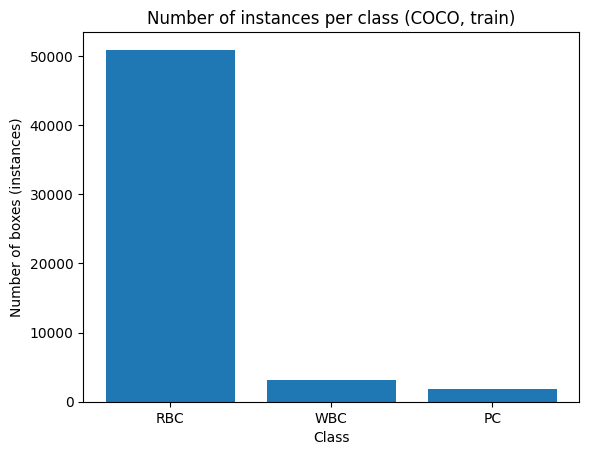

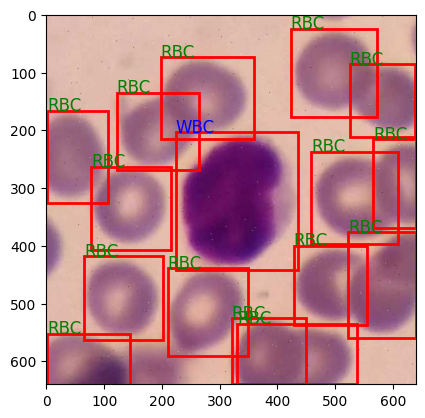

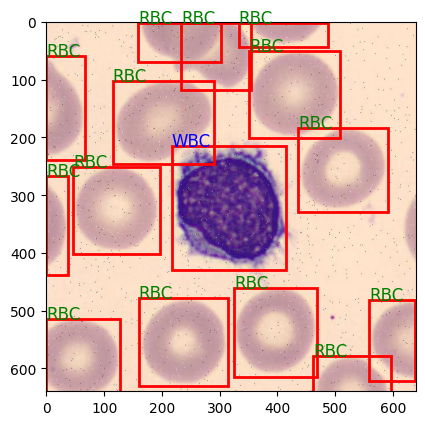

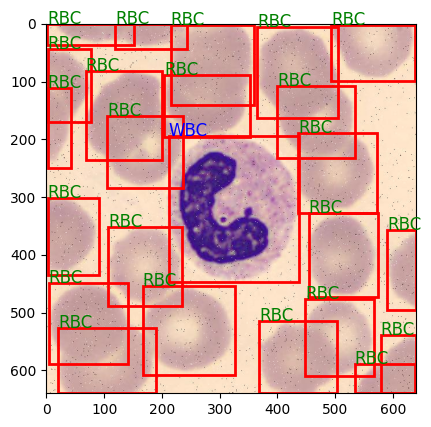

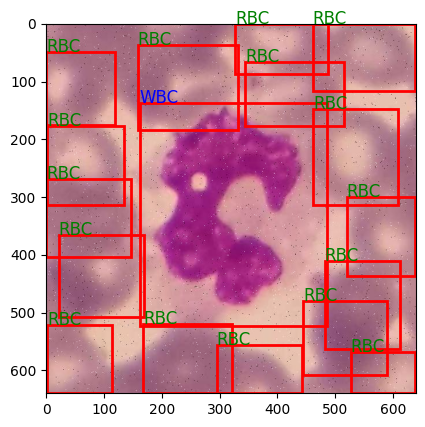

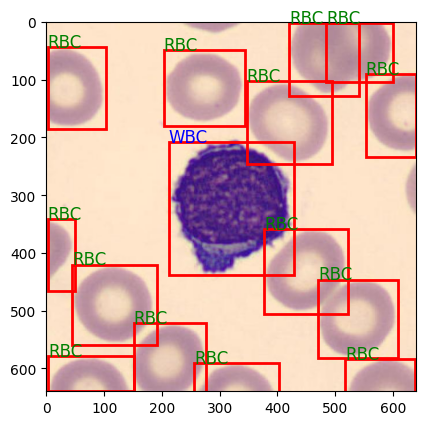

In [14]:
from skimage import io
import matplotlib.pyplot as plt

COLORS = {"PC": "red", "RBC": "green", "WBC": "blue"}

coco = json.load(open(os.path.join(coco_root_path, "train/_annotations.coco.json")))
cat_names = {c["id"]: c["name"] for c in coco["categories"]}
print(f'Number of images: {len(coco["images"])}')
print(f'Number of annotations: {len(coco["annotations"])}')

# class distribution (each annotation is one box = one cell instance)
class_counts = {}
for annotation in coco["annotations"]:
    name = cat_names[annotation["category_id"]]
    class_counts[name] = class_counts.get(name, 0) + 1
print(class_counts)

plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel("Class")
plt.ylabel("Number of boxes (instances)")
plt.title("Number of instances per class (COCO, train)")
plt.show()

# 5 images with their boxes. COCO bbox = [x_min, y_min, width, height] in pixels
anns_by_img = {}
for annotation in coco["annotations"]:
    anns_by_img.setdefault(annotation["image_id"], []).append(annotation)

for img in coco["images"][:5]:
    image = io.imread(os.path.join(coco_root_path, "train", img["file_name"]))
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    for annotation in anns_by_img.get(img["id"], []):
        x, y, w, h = annotation["bbox"]
        name = cat_names[annotation["category_id"]]
        ax.add_patch(plt.Rectangle((x, y), w, h, fill=False, edgecolor="red", linewidth=2))
        ax.text(x, y, name, color=COLORS[name], fontsize=12)
    plt.show()

Do the same with the new YOLO version

Steps:
* Load all image-annotation pairs from `train` and print/plot
    * number of images
    * number of annotations
    * class distribution (number of images per class)
* Load N=5 images and plot them with bounding boxes

Number of images: 3027
Number of annotation files: 3027
Number of annotations: 55881
{'PC': 1803, 'RBC': 50895, 'WBC': 3183}


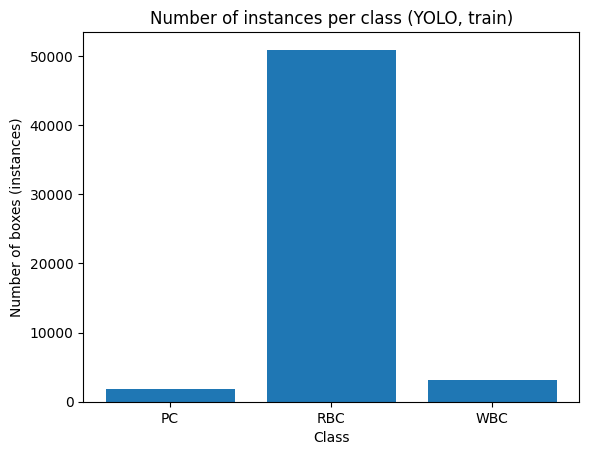

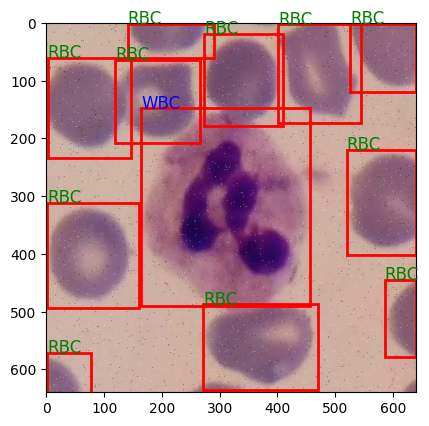

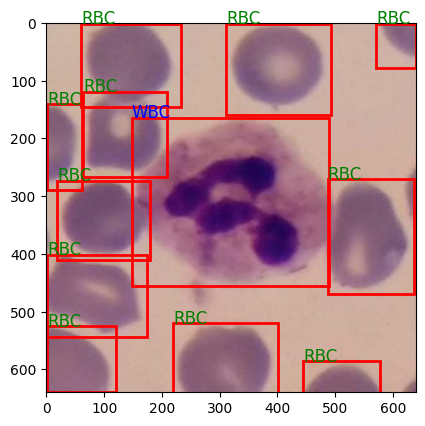

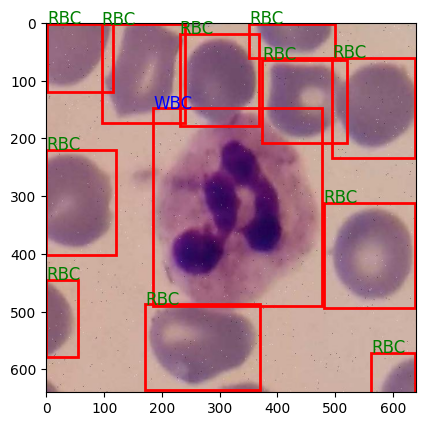

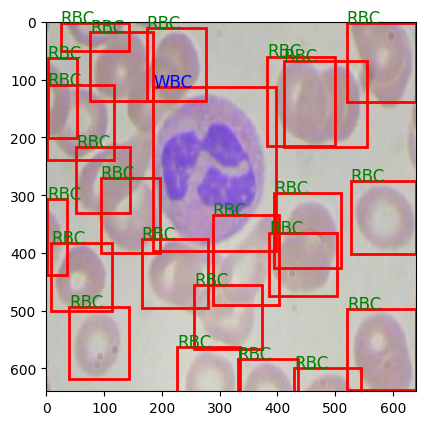

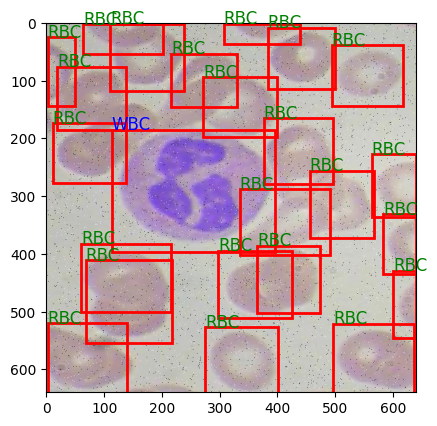

In [15]:
# load all image-annotation pairs from train (YOLO version)
image_dir = os.path.join(yolo_root_path, "train/images")
image_paths, label_paths = [], []
for name in sorted(os.listdir(image_dir)):
    image_paths.append(os.path.join(image_dir, name))
    label_paths.append(os.path.join(yolo_root_path, "train/labels", os.path.splitext(name)[0] + ".txt"))

print(f"Number of images: {len(image_paths)}")
print(f"Number of annotation files: {len(label_paths)}")

number_of_annotations = 0
class_counts = {}
for label_path in label_paths:
    with open(label_path) as f:
        for line in f.read().splitlines():
            class_id = int(line.split()[0])
            class_counts[class_id] = class_counts.get(class_id, 0) + 1
            number_of_annotations += 1
print(f"Number of annotations: {number_of_annotations}")

class_counts = {CLASS_NAMES[k]: v for k, v in sorted(class_counts.items())}
print(class_counts)
plt.bar(class_counts.keys(), class_counts.values())
plt.xlabel("Class")
plt.ylabel("Number of boxes (instances)")
plt.title("Number of instances per class (YOLO, train)")
plt.show()

# 5 images with boxes. YOLO line = class x_center y_center width height, relative to the image
for image_path, label_path in list(zip(image_paths, label_paths))[:5]:
    image = io.imread(image_path)
    H, W = image.shape[:2]
    fig, ax = plt.subplots(1)
    ax.imshow(image)
    with open(label_path) as f:
        for line in f.read().splitlines():
            class_id, xc, yc, w, h = [float(v) for v in line.split()]
            xc, yc, w, h = xc * W, yc * H, w * W, h * H  # back to pixels
            name = CLASS_NAMES[int(class_id)]
            ax.add_patch(plt.Rectangle((xc - w / 2, yc - h / 2), w, h, fill=False, edgecolor="red", linewidth=2))
            ax.text(xc - w / 2, yc - h / 2, name, color=COLORS[name], fontsize=12)
    plt.show()

# Customize YOLO ("yolo11n") model

In [16]:
from ultralytics import YOLO
import torch

# Apple Silicon GPU (MPS) if available, else CUDA, else CPU
device = "mps" if torch.backends.mps.is_available() else (0 if torch.cuda.is_available() else "cpu")
print("device:", device)

model = YOLO("yolo11n.yaml")  # architecture only, random weights -> training from scratch
# model = YOLO("yolo11n.pt")  # alternative: fine-tune from COCO-pretrained weights (converges much faster)

device: mps


### Model training (from scratch)

In [17]:
# https://docs.ultralytics.com/modes/train/#train-settings
# NOTE: 50 epochs from scratch takes about 1.5-2 hours on an M2 Pro (MPS), ~2 min per epoch. Lower EPOCHS to try it first.
EPOCHS = 50
RUN_NAME = "from_scratch_50e_v1"

model.train(
    data=os.path.join(yolo_root_path, "data.yaml"),
    project=runs_path,  # -> Set9/runs/detect/<RUN_NAME>
    name=RUN_NAME,
    exist_ok=True,  # reuse the folder instead of creating from_scratch_50e_v12, ...
    epochs=EPOCHS,
    batch=16,
    imgsz=640,
    classes=[0, 1, 2],
    device=device,
    plots=True,
)

Ultralytics 8.4.216 🚀 Python-3.10.22 torch-2.14.1 MPS (Apple M2 Pro)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=[0, 1, 2], close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/blood_cell.v1i.yolov11/data.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.yaml, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=from_s

/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for thi

       1/50       5.3G      2.989      3.262      3.674         59        640: 100% ━━━━━━━━━━━━ 190/190 1.6it/s 2:010.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.0it/s 4.5s0.5ss
                   all        288       5345      0.673      0.423      0.322      0.147

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for thi

       2/50      5.31G      1.564      1.303          2         90        640: 100% ━━━━━━━━━━━━ 190/190 1.6it/s 1:560.7ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.9it/s 4.7s0.5ss
                   all        288       5345      0.831      0.768      0.881      0.583

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for thi

... (92 outputs left out)

      49/50      5.28G     0.6013     0.3461      1.086         40        640: 100% ━━━━━━━━━━━━ 190/190 1.3it/s 2:250.8ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.4it/s 6.6s0.6ss
                   all        288       5345      0.945      0.944      0.973      0.818

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      50/50      4.24G     0.6191     0.3591      1.104        225        640: 0% ──────────── 0/190  2.4s

/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/venv/lib/python3.10/site-packages/torch/autograd/graph.py:1072: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for thi

      50/50      5.32G     0.5983     0.3447      1.085         34        640: 100% ━━━━━━━━━━━━ 190/190 1.3it/s 2:210.6ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 2.0it/s 4.5s0.5ss
                   all        288       5345      0.944      0.946      0.973      0.819

50 epochs completed in 1.978 hours.
Optimizer stripped from /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/runs/detect/from_scratch_50e_v1/weights/last.pt, 5.5MB
Optimizer stripped from /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/runs/detect/from_scratch_50e_v1/weights/best.pt, 5.5MB

Validating /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/runs/detect/from_scratch_50e_v1/weights/best.pt...
Ultralytics 8.4.216 🚀 Python-3.10.22 torch-2.14.1 MPS (Apple M2 Pro)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  m

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x126fea470>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04804

best weights: /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/runs/detect/from_scratch_50e_v1/weights/best.pt
['BoxF1_curve.png', 'BoxPR_curve.png', 'BoxP_curve.png', 'BoxR_curve.png', 'args.yaml', 'confusion_matrix.png', 'confusion_matrix_normalized.png', 'labels.jpg', 'results.csv', 'results.png', 'train_batch0.jpg', 'train_batch1.jpg', 'train_batch2.jpg', 'train_batch7600.jpg', 'train_batch7601.jpg', 'train_batch7602.jpg', 'val_batch0_labels.jpg', 'val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'val_batch2_labels.jpg', 'val_batch2_pred.jpg', 'weights']


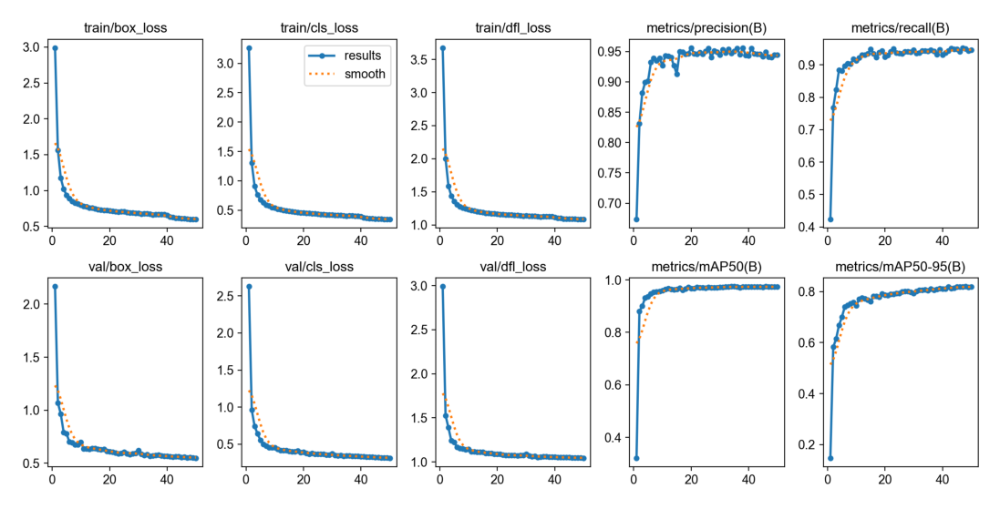

In [22]:
# The model is saved automatically: weights/best.pt (best validation mAP) and weights/last.pt
run_dir = os.path.join(runs_path, RUN_NAME)
print("best weights:", os.path.join(run_dir, "weights", "best.pt"))
print(sorted(os.listdir(run_dir)))

# training curves: losses and validation precision / recall / mAP per epoch
plt.figure(figsize=(14, 7))
plt.imshow(io.imread(os.path.join(run_dir, "results.png")))
plt.axis("off")
plt.show()

# Model Evaluation

If you restarted the kernel, run the paths cell in *Prepare data* first, then continue here.

In [23]:
from ultralytics import YOLO
import torch
import os

# Works after a kernel restart too (only needs the setup cell with the paths)
RUN_NAME = "from_scratch_50e_v1"
run_dir = os.path.join(runs_path, RUN_NAME)
model = YOLO(os.path.join(run_dir, "weights", "best.pt"))

#### Qualitative evaluation


01e4af27-0d62-557e-b967-cd665b590d45_jpg...  prediction time: 0.101 s


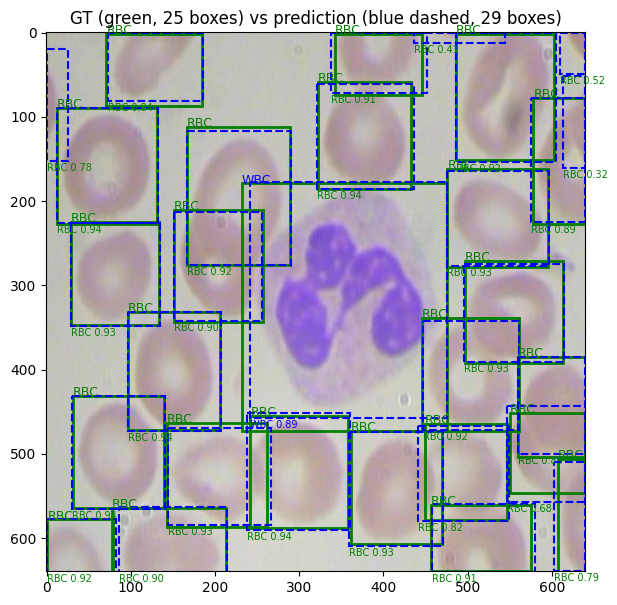

02db46d5-f0f3-511c-b2cc-e907946e88e2_jpg...  prediction time: 0.049 s


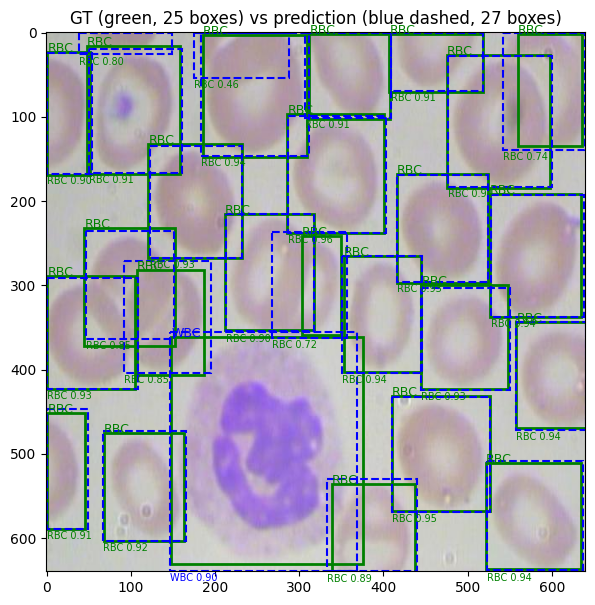

035e0876-5358-5118-a956-116f8af710e4_jpg...  prediction time: 0.056 s


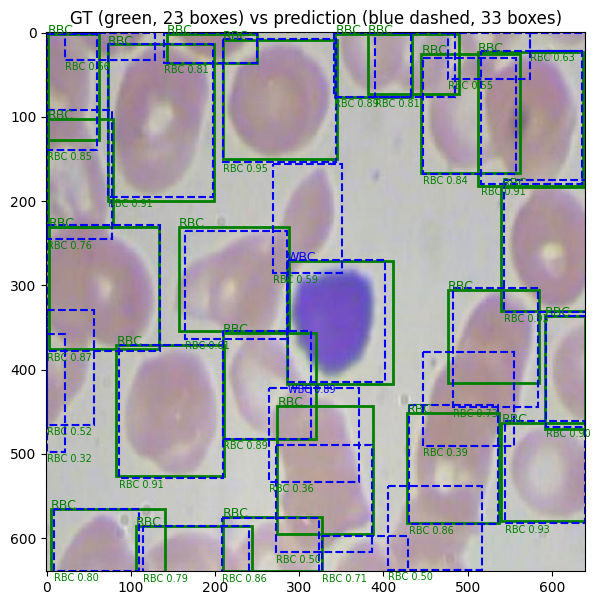

0434941c-bce6-5060-b800-748937b7ea97_jpg...  prediction time: 0.064 s


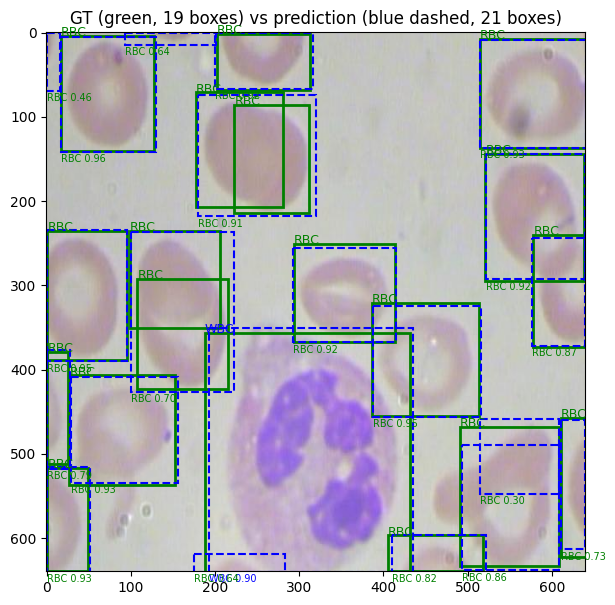

04456893-a20e-59df-b157-42f4ddcb78f8_jpg...  prediction time: 0.086 s


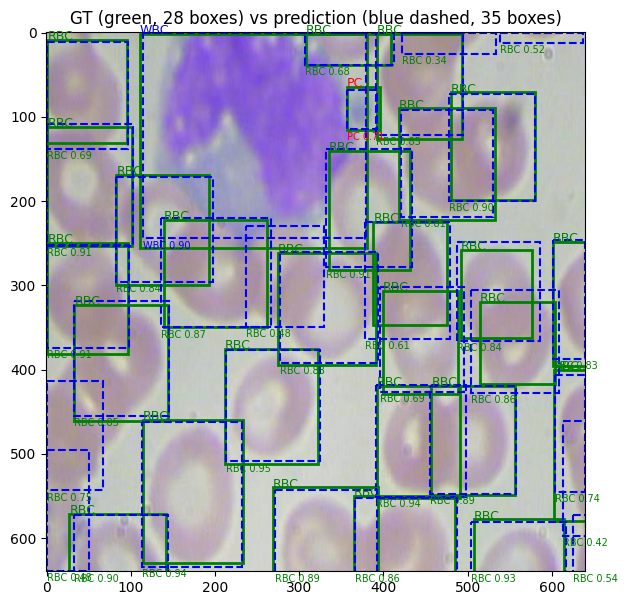

In [24]:
from skimage import io
import matplotlib.pyplot as plt
import time

test_image_dir = os.path.join(yolo_root_path, "test/images")
test_label_dir = os.path.join(yolo_root_path, "test/labels")
test_images = sorted(os.listdir(test_image_dir))
COLORS = {"PC": "red", "RBC": "green", "WBC": "blue"}

for name in test_images[:5]:
    image_path = os.path.join(test_image_dir, name)
    label_path = os.path.join(test_label_dir, os.path.splitext(name)[0] + ".txt")
    image = io.imread(image_path)
    H, W = image.shape[:2]
    with open(label_path) as f:
        labels = f.read().splitlines()

    start_time = time.time()
    with torch.no_grad():
        predict = model.predict(image_path, verbose=False)
    print(f"{name[:40]}...  prediction time: {time.time() - start_time:.3f} s")

    fig, ax = plt.subplots(1, figsize=(7, 7))
    ax.imshow(image)

    # ground truth: YOLO format (relative centre + size) -> pixels, solid green
    for label in labels:
        class_id, xc, yc, w, h = [float(v) for v in label.split()]
        xc, yc, w, h = xc * W, yc * H, w * W, h * H
        cls_name = CLASS_NAMES[int(class_id)]
        ax.add_patch(plt.Rectangle((xc - w / 2, yc - h / 2), w, h, fill=False, edgecolor="green", linewidth=2))
        ax.text(xc - w / 2, yc - h / 2, cls_name, color=COLORS[cls_name], fontsize=9)

    # predictions: box.xyxy = corners in pixels, dashed blue, with confidence
    for box in predict[0].boxes:
        x1, y1, x2, y2 = box.xyxy[0].tolist()
        cls_name = CLASS_NAMES[int(box.cls[0])]
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="blue",
                                   linewidth=1.5, linestyle="--"))
        ax.text(x1, y2 + 12, f"{cls_name} {float(box.conf[0]):.2f}", color=COLORS[cls_name], fontsize=7)

    ax.set_title(f"GT (green, {len(labels)} boxes) vs prediction (blue dashed, {len(predict[0].boxes)} boxes)")
    plt.show()

### Quantitiatve evaluation

* Plot Precision-Recall Curve
* Plot False-Positives-Per-Image Curve
* Print a table with mAP@0.5, mAP@0.5-0.9

We can use the built-in evaluation methods from the YOLO library, which is shown below. But we should also learn to implement these metrics from scratch, so we will do that as well.

In [25]:
# Built-in evaluation on the TEST split (never seen during training)
val_metrics = model.val(
    data=os.path.join(yolo_root_path, "data.yaml"),
    split="test",
    project=runs_path,
    name="test_eval",
    exist_ok=True,
    device=device if "device" in globals() else None,
)
print(f"mAP@0.5      = {val_metrics.box.map50:.3f}")
print(f"mAP@0.5:0.95 = {val_metrics.box.map:.3f}")
for i, name in enumerate(CLASS_NAMES):
    print(f"  AP@0.5:0.95 {name}: {val_metrics.box.maps[i]:.3f}")

Ultralytics 8.4.216 🚀 Python-3.10.22 torch-2.14.1 MPS (Apple M2 Pro)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 160.6±160.3 MB/s, size: 24.7 KB)
val: Scanning /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/blood_cell.v1i.yolov11/test/labels... 144 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 144/144 2.6Kit/s 0.1s
WARNING ⚠️ val: Failed to save cache to /Users/clara/Master/CV/CV-MAI-2026-27-ForensicsApp/Set9/blood_cell.v1i.yolov11/test/labels.cache: Can't pickle <built-in function _reconstruct>: import of module 'numpy._core.multiarray' failed
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 4.3it/s 2.1s0.2s
                   all        144       2678      0.958      0.959      0.983      0.838
                    PC         51         91      0.953      0.912      0.968      0.755
                   RBC        144     

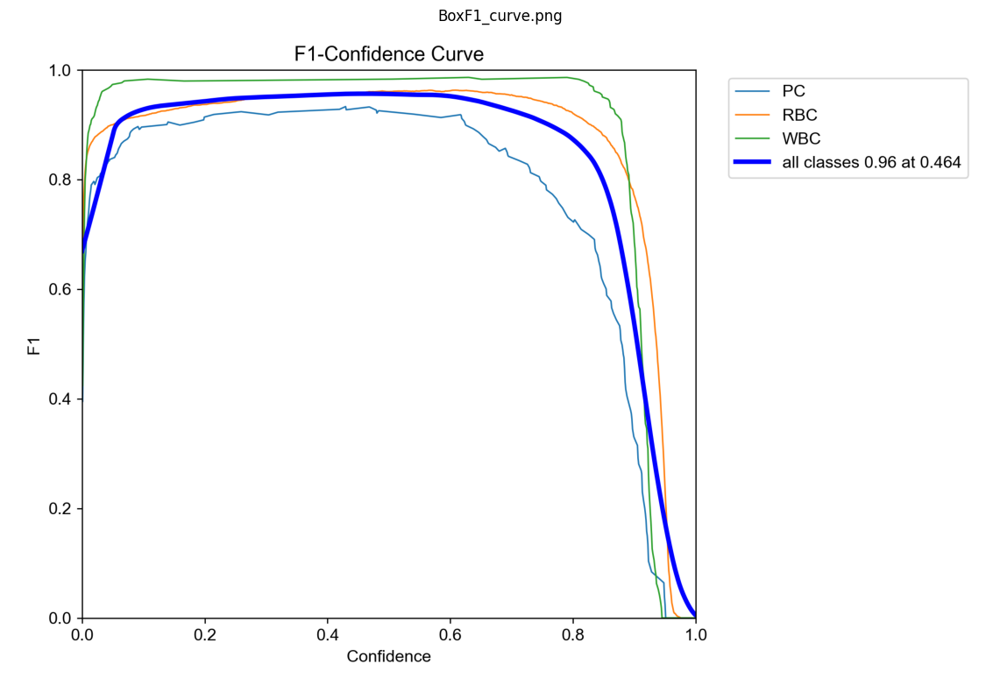

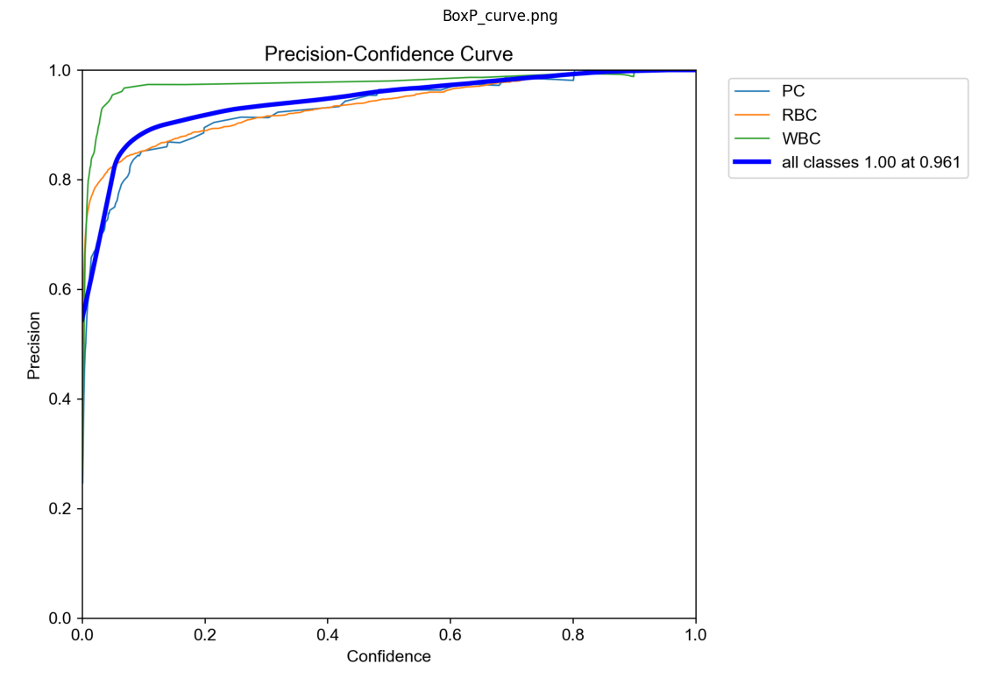

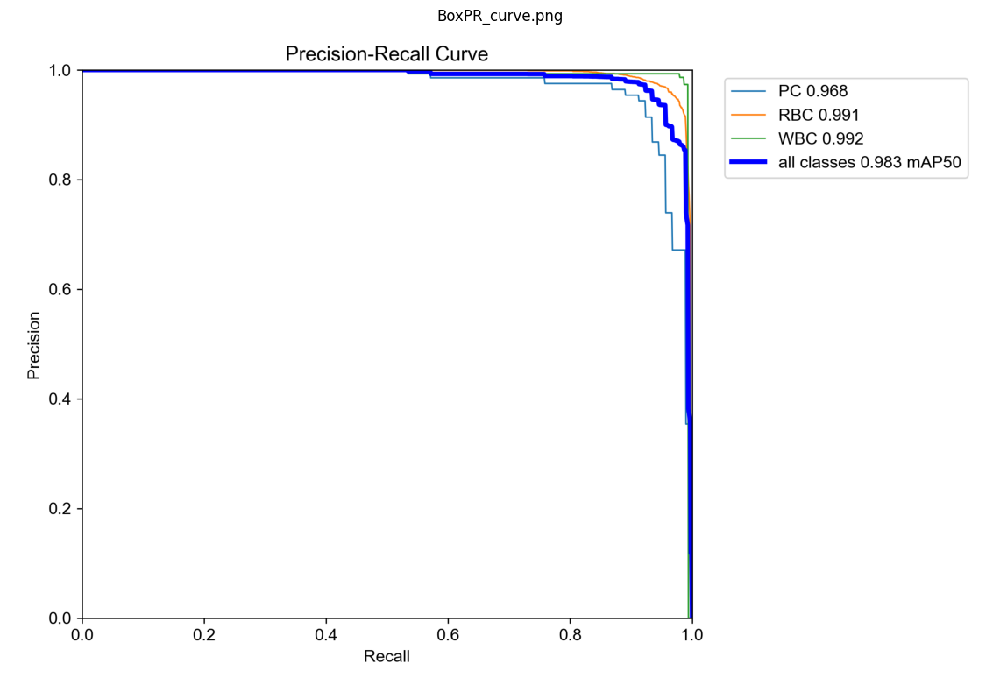

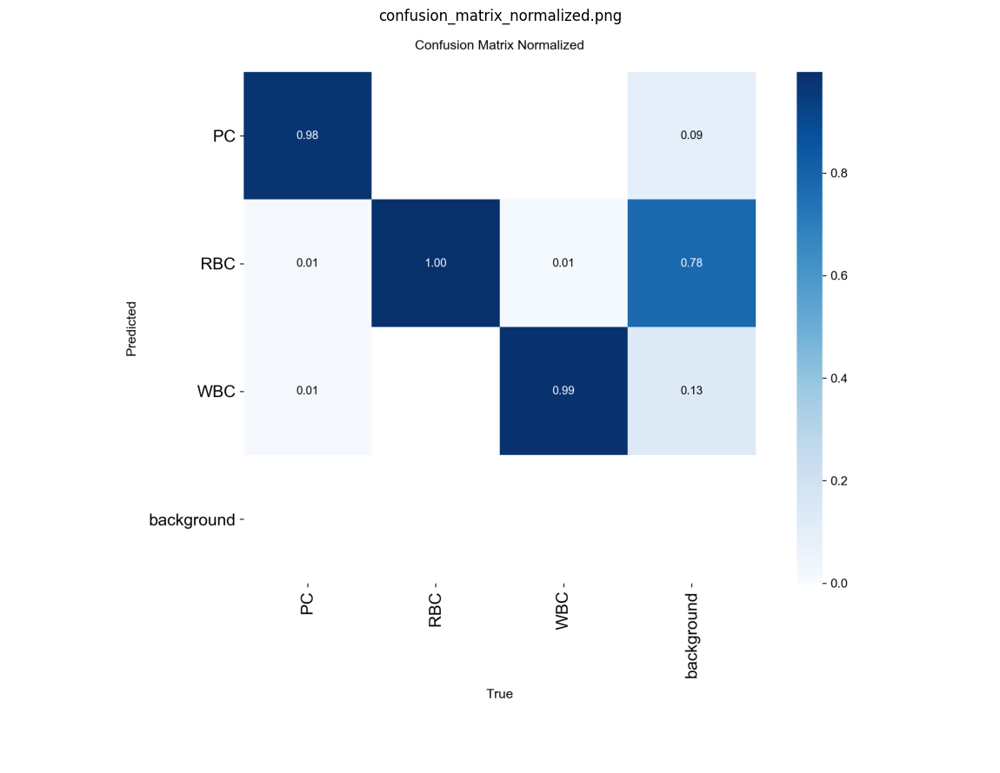

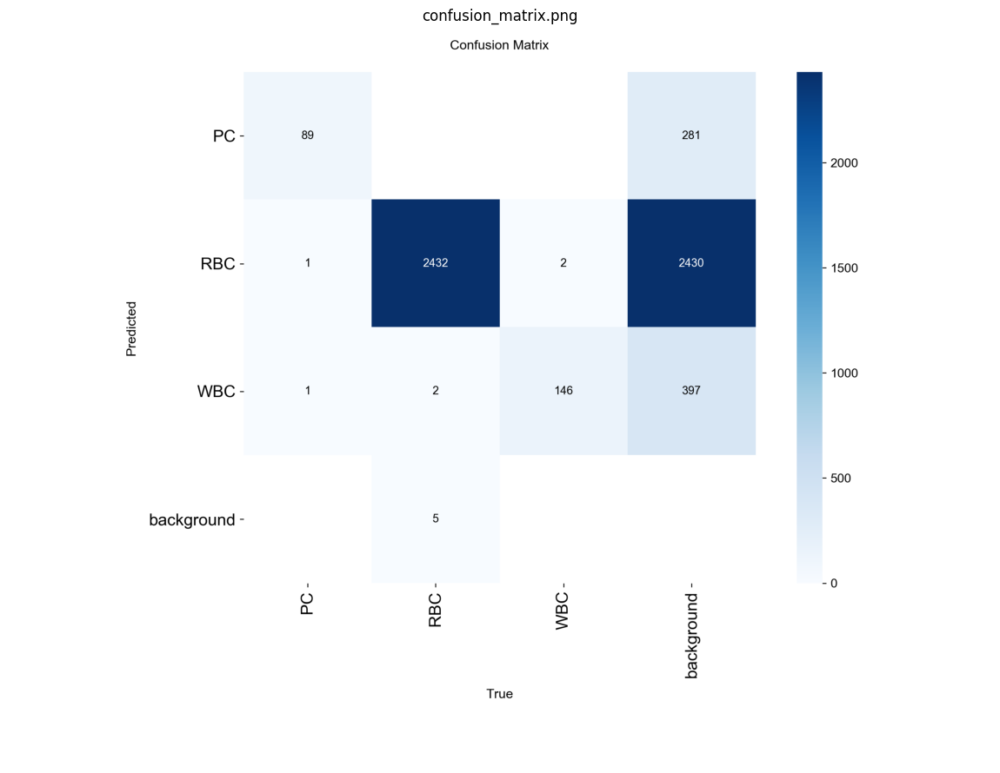

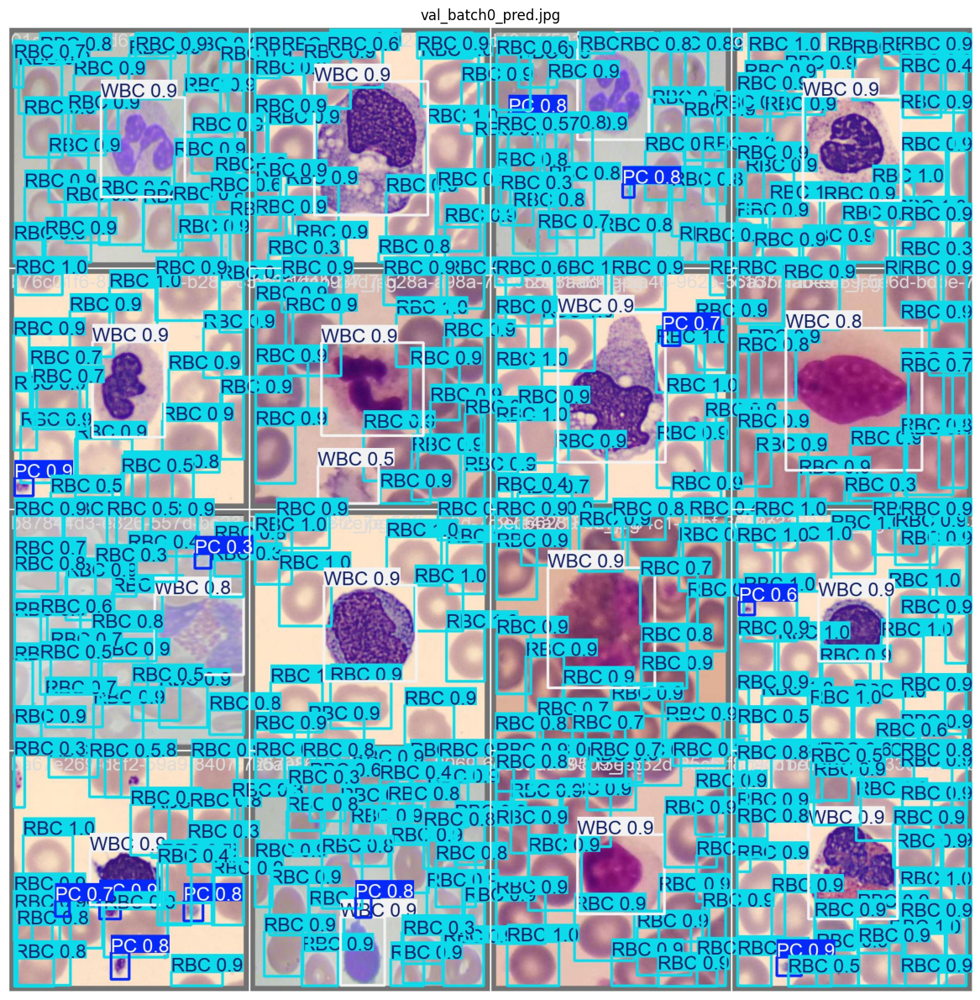

In [30]:
%matplotlib inline
res_path = str(val_metrics.save_dir)  # folder where model.val() wrote its plots

plots = ["BoxF1_curve.png", "BoxP_curve.png", "BoxPR_curve.png",
         "confusion_matrix_normalized.png", "confusion_matrix.png", "val_batch0_pred.jpg"]
plots = [p for p in plots if os.path.exists(os.path.join(res_path, p))]

# one plot per row, full width
for res_plot in plots:
    img = io.imread(os.path.join(res_path, res_plot))
    h, w = img.shape[:2]
    plt.figure(figsize=(12, 12 * h / w))
    plt.imshow(img)
    plt.title(res_plot)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [31]:
# The same metrics implemented from scratch, plus the FPPI curve
import numpy as np
import pandas as pd


def yolo_to_xyxy(rows, W, H):
    """YOLO rows (class, xc, yc, w, h), relative -> classes and pixel corners (x1, y1, x2, y2)."""
    c, xc, yc, w, h = rows.T
    return c.astype(int), np.stack([(xc - w / 2) * W, (yc - h / 2) * H,
                                    (xc + w / 2) * W, (yc + h / 2) * H], axis=1)


def box_iou(a, b):
    """IoU between every box in a (N, 4) and every box in b (M, 4) -> (N, M)."""
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0])
    iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2])
    iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / np.maximum(area_a[:, None] + area_b[None, :] - inter, 1e-9)


def collect_predictions(model_path, image_folder, label_folder, conf=0.001):
    """Run the model ONCE on every image; keep GT and detections so we can match at any IoU.
    conf=0.001 (like model.val) keeps low-confidence boxes, needed for the full PR curve."""
    model = YOLO(model_path)
    per_image = []
    for r in model.predict(image_folder, stream=True, imgsz=640, conf=conf, verbose=False):
        H, W = r.orig_shape
        lab = os.path.join(label_folder, os.path.splitext(os.path.basename(r.path))[0] + ".txt")
        gt = np.loadtxt(lab, ndmin=2) if os.path.exists(lab) else np.zeros((0, 5))
        gt_cls, gt_xyxy = yolo_to_xyxy(gt.reshape(-1, 5), W, H)
        per_image.append({
            "gt_cls": gt_cls, "gt_xyxy": gt_xyxy,
            "det_cls": r.boxes.cls.cpu().numpy().astype(int),
            "det_conf": r.boxes.conf.cpu().numpy(),
            "det_xyxy": r.boxes.xyxy.cpu().numpy(),
        })
    return per_image


def match_detections(per_image, iou_thr=0.5):
    """Label every detection TP or FP. Per image and per class, detections are taken by
    decreasing confidence; each one is a TP if its best GT box of the SAME class has
    IoU >= iou_thr and that GT box was not matched before (one detection per GT)."""
    rows = []
    n_gt = {c: 0 for c in range(len(CLASS_NAMES))}
    for im in per_image:
        for c in n_gt:
            gts = im["gt_xyxy"][im["gt_cls"] == c]
            n_gt[c] += len(gts)
            mask = im["det_cls"] == c
            confs, dets = im["det_conf"][mask], im["det_xyxy"][mask]
            order = np.argsort(-confs)
            ious = box_iou(dets[order], gts) if len(gts) else np.zeros((len(order), 0))
            used = np.zeros(len(gts), dtype=bool)
            for k, d in enumerate(order):
                tp = 0
                if len(gts):
                    j = int(np.argmax(ious[k]))
                    if ious[k, j] >= iou_thr and not used[j]:
                        used[j], tp = True, 1
                rows.append([c, confs[d], tp, 1 - tp])
    return pd.DataFrame(rows, columns=["cls", "conf", "tp", "fp"]), n_gt


def pr_points(df, n_gt_total):
    """Precision and recall after each detection, sorted by confidence (one point per threshold)."""
    df = df.sort_values("conf", ascending=False)
    tp_cum, fp_cum = df["tp"].cumsum().values, df["fp"].cumsum().values
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1e-9)
    recall = tp_cum / max(n_gt_total, 1)  # divide by ALL ground-truth boxes, not by the TPs found
    return precision, recall, fp_cum, tp_cum


def average_precision(precision, recall):
    """COCO-style 101-point interpolated AP (area under the PR curve with its precision envelope)."""
    mrec = np.concatenate(([0.0], recall, [1.0]))
    mpre = np.concatenate(([1.0], precision, [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))  # make precision monotonically decreasing
    x = np.linspace(0, 1, 101)
    trapezoid = getattr(np, "trapezoid", None) or np.trapz  # numpy 2 renamed trapz
    return trapezoid(np.interp(x, mrec, mpre), x)


def plot_pr_curve(df, n_gt):
    plt.figure()
    for c, name in enumerate(CLASS_NAMES):
        p, r, _, _ = pr_points(df[df["cls"] == c], n_gt[c])
        plt.plot(r, p, label=f"{name} (AP={average_precision(p, r):.3f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("PR curve (IoU = 0.5)")
    plt.xlim(0, 1)
    plt.ylim(0, 1.02)
    plt.legend()
    plt.grid(True)
    plt.show()


def plot_fppi_tpr(df, n_gt, num_images):
    """TPR (= recall) vs average number of false positives per image, all classes together."""
    _, recall, fp_cum, _ = pr_points(df, sum(n_gt.values()))
    plt.figure()
    plt.semilogx(fp_cum / num_images, recall)
    plt.xlabel("False positives per image (FPPI, log scale)")
    plt.ylabel("TPR (recall)")
    plt.title("FPPI - TPR (IoU = 0.5)")
    plt.grid(True, which="both")
    plt.show()


def compute_map_table(per_image, iou_thresholds):
    """AP per class and mAP, re-matching the detections at every IoU threshold."""
    records = []
    for iou in iou_thresholds:
        df, n_gt = match_detections(per_image, iou)
        aps = [average_precision(*pr_points(df[df["cls"] == c], n_gt[c])[:2]) for c in n_gt]
        records.append([round(float(iou), 2), *aps, np.mean(aps)])
    return pd.DataFrame(records, columns=["IoU", *[f"AP_{n}" for n in CLASS_NAMES], "mAP"])

In [32]:
model_path = os.path.join(run_dir, "weights", "best.pt")
image_folder = os.path.join(yolo_root_path, "test/images")
label_folder = os.path.join(yolo_root_path, "test/labels")

per_image = collect_predictions(model_path, image_folder, label_folder)  # inference only once
results, n_gt = match_detections(per_image, iou_thr=0.5)
print("GT boxes per class:", {CLASS_NAMES[c]: n for c, n in n_gt.items()})
results.head()

GT boxes per class: {'PC': 91, 'RBC': 2439, 'WBC': 148}


,cls,conf,tp,fp
0,0,0.002243,0,1
1,1,0.941303,1,0
2,1,0.941166,1,0
3,1,0.938494,1,0
4,1,0.938270,1,0


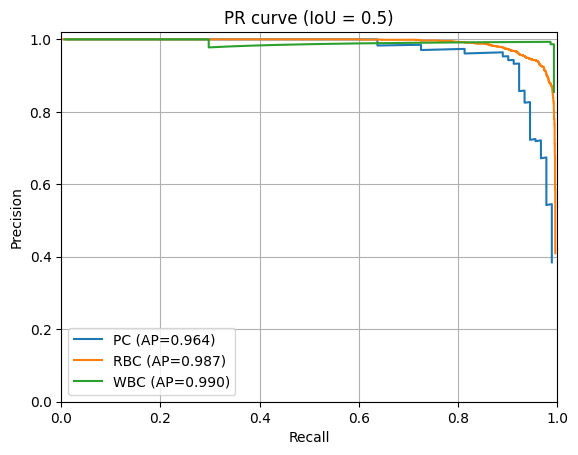

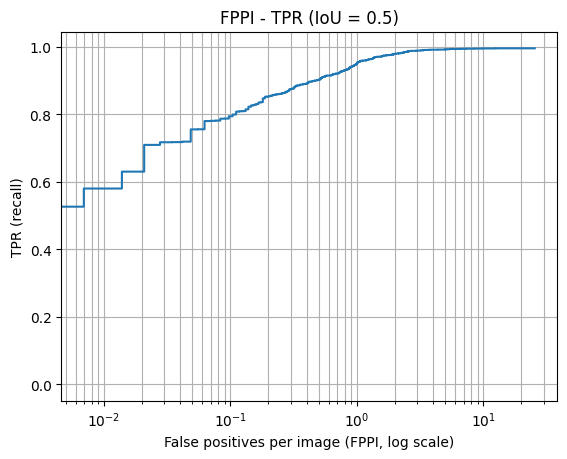

 IoU    AP_PC   AP_RBC   AP_WBC      mAP
0.50 0.963746 0.987130 0.990172 0.980349
0.55 0.963746 0.986582 0.990172 0.980167
0.60 0.959983 0.983715 0.990172 0.977957
0.65 0.947702 0.977675 0.990172 0.971850
0.70 0.939021 0.965097 0.990172 0.964763
0.75 0.914128 0.952203 0.986588 0.950973
0.80 0.829395 0.928370 0.978225 0.911997
0.85 0.696890 0.873751 0.941060 0.837234
0.90 0.455474 0.776348 0.752953 0.661592
0.95 0.057072 0.427996 0.331090 0.272052

mAP@0.5      = 0.980   (built-in: 0.983)
mAP@0.5:0.95 = 0.851   (built-in: 0.838)


In [33]:
plot_pr_curve(results, n_gt)
plot_fppi_tpr(results, n_gt, num_images=len(per_image))

map_table = compute_map_table(per_image, np.arange(0.5, 0.96, 0.05))
print(map_table.to_string(index=False))
print(f"\nmAP@0.5      = {map_table['mAP'].iloc[0]:.3f}   (built-in: {val_metrics.box.map50:.3f})"
      if "val_metrics" in globals() else f"\nmAP@0.5      = {map_table['mAP'].iloc[0]:.3f}")
print(f"mAP@0.5:0.95 = {map_table['mAP'].mean():.3f}"
      + (f"   (built-in: {val_metrics.box.map:.3f})" if "val_metrics" in globals() else ""))